# Limpeza da base de manutenção corretiva programada — ZM02

Este notebook documenta e executa o pipeline de limpeza das ordens de manutenção corretiva programada ZM02. A base original é preservada e todas as decisões relevantes ficam registradas para auditoria e integração futura.

Etapas: importação e comparação das fontes, diagnóstico, padronização estrutural, tratamento temporal e textual, análise de duplicidades, sinalização de durações atípicas, preparação final, validação e exportação.

## 1. Importação e comparação das fontes

As duas extrações disponíveis são comparadas antes da escolha da fonte. Como possuem o mesmo conteúdo, somente a primeira é utilizada; as bases não são concatenadas.

In [1]:
import pandas as pd

caminho_1 = "../../data/Corretiva Programada/Ordens do SAP -Corretiva programada (ZM02).XLSX"
caminho_2 = "../../data/Corretiva Programada/Ordens do SAP -Corretiva programada (ZM02)- 2.XLSX"

df_1 = pd.read_excel(caminho_1, sheet_name="Sheet1")
df_2 = pd.read_excel(caminho_2, sheet_name="Sheet1")

print("Arquivo 1:", df_1.shape)
print("Arquivo 2:", df_2.shape)
print("Mesmas colunas:", df_1.columns.equals(df_2.columns))

print("Conteúdo exatamente igual:", df_1.equals(df_2))

df = df_1.copy()
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

df.head()

Arquivo 1: (1163, 28)
Arquivo 2: (1163, 28)
Mesmas colunas: True
Conteúdo exatamente igual: True
Linhas: 1163
Colunas: 28


,Tipo de Nota,Nota,Ordem,Indisponível,Falha,IQM,Analisada,Comentários Classificação Engenharia,Perfil do catálogo,Descrição,...,Centro de Trabalho Responsável,Sintoma,Objeto,Defeito,Causa,Ação,Data Análise,Hora Análise,Encerram.por Data,Hora de Encerramento
0,Z2,15069252,54081268.0,NaN,NaN,NaN,NaN,NaN,6PSD,Porta PCC-PSD a,...,SP04IBUT,PDM NÃO ABRE,"ESTRUTURA, ACABAMENTO, E ACESSÓRIOS DO P",PORTA DESAJUSTADA,FALTA FIXACAO,FIXADO,NaT,00:00:00,2026-01-25,16:50:18
1,Z2,14647619,53659484.0,NaN,NaN,NaN,NaN,NaN,6PSD,PDMs plat 1 e 2 com falha momentânea.,...,SP04IBUT,MAU CONTATO,SWITCK DE COMUNICAÇÃO,SEM CONEXAO ELETRICA,ERRO DE SOFTWARE,RESETADO E TESTADO,NaT,00:00:00,2025-06-01,04:36:44
2,Z2,14682623,53694340.0,NaN,NaN,NaN,NaN,NaN,6PSD,Rele painel SSE intermitente,...,SP04IBUT,FACHADA PSD SEM ALIMENTAÇÃO,DISPOSITIVO DE PROTECAO,CONVERSOR DE TENSAO AVARIADO,OPERACAO INDEVIDA,SUBSTITUIDO(A),NaT,00:00:00,2025-06-19,05:10:12
3,Z2,14864269,53874165.0,NaN,NaN,NaN,NaN,NaN,6PSD,Multimedidor SSE moldura solta,...,SP04IBUT,ESTRUTURA DANIFICADA,MULTIMEDIDOR,VIDRO QUEBRADO,DESGASTE,SUBSTITUIDO(A),NaT,00:00:00,2025-09-30,14:53:22
4,Z2,13390549,52423535.0,NaN,NaN,NaN,NaN,NaN,6PSD,Volume do P.A baixo.,...,SP04IBUT,SERVIDOR SEM COMUNICACAO,SWITCK DE COMUNICAÇÃO,BAIXA ISOLACAO,FALTA FIXACAO,APERTADO(A),NaT,00:00:00,2023-07-27,13:52:02


## 2. Diagnóstico inicial

O diagnóstico mede dimensões, tipos, ausências e qualidade dos identificadores antes de qualquer transformação.

In [2]:
df.info()

diagnostico_identificadores = pd.Series({
    "linhas": len(df),
    "notas_ausentes": df["Nota"].isna().sum(),
    "notas_distintas": df["Nota"].nunique(dropna=True),
    "notas_repetidas_excedentes": (
        df["Nota"].notna() & df["Nota"].duplicated()
    ).sum(),
    "ordens_ausentes": df["Ordem"].isna().sum(),
    "ordens_distintas": df["Ordem"].nunique(dropna=True),
    "ordens_repetidas_excedentes": (
        df["Ordem"].notna() & df["Ordem"].duplicated()
    ).sum(),
    "linhas_totalmente_duplicadas": df.duplicated().sum()
})

diagnostico_identificadores

<class 'pandas.DataFrame'>
RangeIndex: 1163 entries, 0 to 1162
Data columns (total 28 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Tipo de Nota                          1163 non-null   str           
 1   Nota                                  1163 non-null   int64         
 2   Ordem                                 1158 non-null   float64       
 3   Indisponível                          1 non-null      str           
 4   Falha                                 0 non-null      float64       
 5   IQM                                   0 non-null      float64       
 6   Analisada                             1 non-null      str           
 7   Comentários Classificação Engenharia  1 non-null      str           
 8   Perfil do catálogo                    1163 non-null   str           
 9   Descrição                             1163 non-null   str           
 10  Local de In

linhas                          1163
notas_ausentes                     0
notas_distintas                 1158
notas_repetidas_excedentes         5
ordens_ausentes                    5
ordens_distintas                1153
ordens_repetidas_excedentes        5
linhas_totalmente_duplicadas       0
dtype: int64

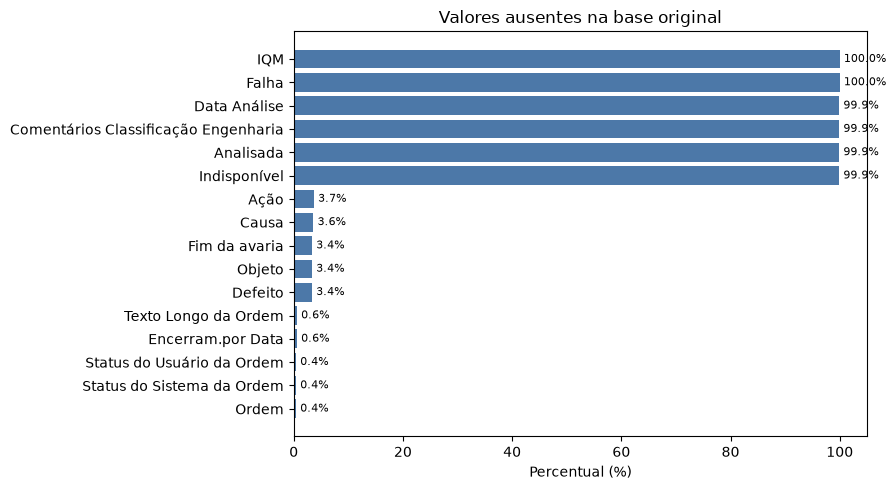

In [3]:
relatorio_ausentes = pd.DataFrame({
    "quantidade": df.isna().sum(),
    "percentual": (df.isna().mean() * 100).round(2)
}).sort_values("percentual", ascending=False)

relatorio_ausentes[
    relatorio_ausentes["quantidade"] > 0
]

ausentes_plot = relatorio_ausentes.query("percentual > 0").sort_values("percentual")

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ausentes_plot.index, ausentes_plot["percentual"], color="#4C78A8")
ax.set(title="Valores ausentes na base original", xlabel="Percentual (%)", ylabel="")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

As colunas `falha` e `iqm` estão completamente vazias. Já `indisponivel`, `analisada`, o comentário de engenharia e a data de análise possuem apenas um registro preenchido. Os cinco registros sem ordem são preservados porque possuem nota, descrição e localização.

## 3. Padronização estrutural

Os nomes são normalizados para `snake_case`, os identificadores são convertidos para texto e a linha original é registrada para rastreabilidade. Somente as colunas 100% vazias são removidas nesta fase.

In [4]:
df_limpo = df.copy()
df_limpo["linha_origem"] = df_limpo.index + 2

import re
import unicodedata

def normalizar_coluna(nome):
    nome = str(nome).strip().lower()
    nome = unicodedata.normalize("NFKD", nome)
    nome = nome.encode("ascii", "ignore").decode("ascii")
    nome = re.sub(r"[^a-z0-9]+", "_", nome)
    return nome.strip("_")

df_limpo.columns = [
    normalizar_coluna(coluna)
    for coluna in df_limpo.columns
]

print("Colunas duplicadas:", df_limpo.columns.duplicated().sum())
df_limpo.columns.tolist()

for coluna in ["nota", "ordem"]:
    df_limpo[coluna] = (
        df_limpo[coluna]
        .astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

df_limpo[["nota", "ordem"]].dtypes

colunas_totalmente_vazias = [
    coluna
    for coluna in df_limpo.columns
    if df_limpo[coluna].isna().all()
]

colunas_totalmente_vazias

df_limpo.drop(
    columns=colunas_totalmente_vazias,
    inplace=True
)

Colunas duplicadas: 0


## 4. Conversão de datas e horários

Datas em texto, datas já reconhecidas pelo pandas e números seriais do Excel são tratados. Os horários são convertidos para intervalos e combinados às respectivas datas.

In [5]:
def converter_data(serie):
    if pd.api.types.is_datetime64_any_dtype(serie):
        return pd.to_datetime(serie, errors="coerce")

    numeros = pd.to_numeric(serie, errors="coerce")
    valores_numericos = numeros.notna()

    datas_texto = pd.to_datetime(
        serie.where(~valores_numericos),
        errors="coerce",
        dayfirst=True
    )

    datas_excel = pd.to_datetime(
        numeros.where(valores_numericos),
        errors="coerce",
        unit="D",
        origin="1899-12-30"
    )

    return datas_texto.fillna(datas_excel)

colunas_data = [
    "inicio_avaria",
    "fim_da_avaria",
    "data_analise",
    "encerram_por_data"
]

for coluna in colunas_data:
    valores_originais = df_limpo[coluna].copy()
    datas_convertidas = converter_data(valores_originais)

    invalidas = valores_originais.notna() & datas_convertidas.isna()

    df_limpo[coluna] = datas_convertidas

    print(f"{coluna}: {invalidas.sum()} valores inválidos")

for coluna in colunas_data:
    print(
        coluna,
        "| ausentes:", df_limpo[coluna].isna().sum(),
        "| mínima:", df_limpo[coluna].min(),
        "| máxima:", df_limpo[coluna].max()
    )

inicio_avaria: 0 valores inválidos
fim_da_avaria: 0 valores inválidos
data_analise: 0 valores inválidos
encerram_por_data: 0 valores inválidos
inicio_avaria | ausentes: 0 | mínima: 2023-01-03 00:00:00 | máxima: 2026-03-28 00:00:00
fim_da_avaria | ausentes: 39 | mínima: 2023-01-07 00:00:00 | máxima: 2026-05-14 00:00:00
data_analise | ausentes: 1162 | mínima: 2026-03-04 00:00:00 | máxima: 2026-03-04 00:00:00
encerram_por_data | ausentes: 7 | mínima: 2023-01-07 00:00:00 | máxima: 2026-05-14 00:00:00


In [6]:
from datetime import time

def converter_hora(valor):
    if pd.isna(valor):
        return pd.NaT

    # Horário já reconhecido pelo Excel/pandas
    if isinstance(valor, time):
        return pd.Timedelta(
            hours=valor.hour,
            minutes=valor.minute,
            seconds=valor.second
        )

    # Horário armazenado como fração de um dia
    try:
        numero = float(valor)

        if 0 <= numero < 1:
            return pd.to_timedelta(numero, unit="D")
    except (TypeError, ValueError):
        pass

    # Horário armazenado como texto
    horario = pd.to_datetime(
        str(valor),
        errors="coerce"
    )

    if pd.isna(horario):
        return pd.NaT

    return pd.Timedelta(
        hours=horario.hour,
        minutes=horario.minute,
        seconds=horario.second
    )

colunas_hora = [
    "hora_inicio_avaria",
    "hora_do_fim_da_avaria",
    "hora_analise",
    "hora_de_encerramento"
]

for coluna in colunas_hora:
    nova_coluna = f"{coluna}_convertida"

    df_limpo[nova_coluna] = (
        df_limpo[coluna].apply(converter_hora)
    )

    invalidos = (
        df_limpo[coluna].notna()
        & df_limpo[nova_coluna].isna()
    )

    print(
        f"{coluna}: {invalidos.sum()} horários inválidos"
    )

df_limpo["inicio_avaria_datetime"] = (
    df_limpo["inicio_avaria"]
    + df_limpo["hora_inicio_avaria_convertida"]
)

df_limpo["fim_avaria_datetime"] = (
    df_limpo["fim_da_avaria"]
    + df_limpo["hora_do_fim_da_avaria_convertida"]
)

df_limpo["analise_datetime"] = (
    df_limpo["data_analise"]
    + df_limpo["hora_analise_convertida"]
)

df_limpo["encerramento_datetime"] = (
    df_limpo["encerram_por_data"]
    + df_limpo["hora_de_encerramento_convertida"]
)

colunas_datetime = [
    "inicio_avaria_datetime",
    "fim_avaria_datetime",
    "analise_datetime",
    "encerramento_datetime"
]

df_limpo[colunas_datetime].head()

validacao_temporal = pd.Series({
    "inicio_ausente": (
        df_limpo["inicio_avaria_datetime"].isna().sum()
    ),
    "fim_ausente": (
        df_limpo["fim_avaria_datetime"].isna().sum()
    ),
    "analise_ausente": (
        df_limpo["analise_datetime"].isna().sum()
    ),
    "encerramento_ausente": (
        df_limpo["encerramento_datetime"].isna().sum()
    ),
    "fim_anterior_inicio": (
        df_limpo["fim_avaria_datetime"]
        < df_limpo["inicio_avaria_datetime"]
    ).sum(),
    "encerramento_anterior_inicio": (
        df_limpo["encerramento_datetime"]
        < df_limpo["inicio_avaria_datetime"]
    ).sum()
})

validacao_temporal

hora_inicio_avaria: 0 horários inválidos
hora_do_fim_da_avaria: 0 horários inválidos
hora_analise: 0 horários inválidos
hora_de_encerramento: 0 horários inválidos


inicio_ausente                     0
fim_ausente                       39
analise_ausente                 1162
encerramento_ausente               7
fim_anterior_inicio                0
encerramento_anterior_inicio       0
dtype: int64

In [7]:
incoerencias_temporais = pd.Series({
    "fim_anterior_inicio": (
        df_limpo["fim_avaria_datetime"] < df_limpo["inicio_avaria_datetime"]
    ).sum(),
    "encerramento_anterior_inicio": (
        df_limpo["encerramento_datetime"] < df_limpo["inicio_avaria_datetime"]
    ).sum(),
})

df_limpo["duracao_avaria_horas"] = (
    df_limpo["fim_avaria_datetime"] - df_limpo["inicio_avaria_datetime"]
).dt.total_seconds().div(3600)

assert incoerencias_temporais.eq(0).all()
incoerencias_temporais

fim_anterior_inicio             0
encerramento_anterior_inicio    0
dtype: int64

Não foram identificados fins ou encerramentos anteriores ao início. As datas de fim ausentes são preservadas e, nesses casos, a duração permanece ausente.

## 5. Limpeza textual e indicadores

Espaços invisíveis e repetições de espaços são normalizados sem corrigir ortografia ou alterar o significado técnico. As marcações `X` são convertidas em indicadores booleanos.

In [8]:
def limpar_texto(serie, maiusculo=False):
    serie = (
        serie.astype("string")
        .str.replace("\u00a0", " ", regex=False)
        .str.replace(r"[ \t]+", " ", regex=True)
        .str.strip()
        .replace("", pd.NA)
    )

    if maiusculo:
        serie = serie.str.upper()

    return serie

colunas_categoricas = [
    "tipo_de_nota",
    "indisponivel",
    "analisada",
    "perfil_do_catalogo",
    "local_de_instalacao",
    "status_do_usuario_da_ordem",
    "status_do_sistema_da_ordem",
    "centro_de_trabalho_responsavel",
    "sintoma",
    "objeto",
    "defeito",
    "causa",
    "acao"
]

for coluna in colunas_categoricas:
    df_limpo[coluna] = limpar_texto(
        df_limpo[coluna],
        maiusculo=True
    )

colunas_descritivas = [
    "comentarios_classificacao_engenharia",
    "descricao",
    "texto_longo_da_ordem"
]

for coluna in colunas_descritivas:
    df_limpo[coluna] = limpar_texto(
        df_limpo[coluna]
    )

colunas_indicadoras = [
    "indisponivel",
    "analisada"
]

for coluna in colunas_indicadoras:
    df_limpo[f"{coluna}_flag"] = (
        df_limpo[coluna]
        .fillna("")
        .eq("X")
        .astype("boolean")
    )

for coluna in colunas_indicadoras:
    print(
        coluna,
        "| marcados:",
        df_limpo[coluna].eq("X").sum(),
        "| verdadeiros:",
        df_limpo[f"{coluna}_flag"].sum(),
        "| ausentes na flag:",
        df_limpo[f"{coluna}_flag"].isna().sum()
    )

indisponivel | marcados: 1 | verdadeiros: 1 | ausentes na flag: 0
analisada | marcados: 1 | verdadeiros: 1 | ausentes na flag: 0


In [9]:
colunas_dominio = [
    "tipo_de_nota",
    "perfil_do_catalogo",
    "indisponivel",
    "analisada",
    "centro_de_trabalho_responsavel",
    "sintoma",
    "objeto",
    "defeito",
    "causa",
    "acao"
]

resumo_categorias = pd.DataFrame({
    "preenchidos": [
        df_limpo[coluna].notna().sum()
        for coluna in colunas_dominio
    ],
    "ausentes": [
        df_limpo[coluna].isna().sum()
        for coluna in colunas_dominio
    ],
    "valores_unicos": [
        df_limpo[coluna].nunique(dropna=True)
        for coluna in colunas_dominio
    ]
}, index=colunas_dominio)

resumo_categorias

for coluna in [
    "tipo_de_nota",
    "perfil_do_catalogo",
    "indisponivel",
    "analisada"
]:
    print(f"\n--- {coluna} ---")
    print(df_limpo[coluna].value_counts(dropna=False))


--- tipo_de_nota ---
tipo_de_nota
Z2    1163
Name: count, dtype: Int64

--- perfil_do_catalogo ---
perfil_do_catalogo
6PSD    1163
Name: count, dtype: Int64

--- indisponivel ---
indisponivel
<NA>    1162
X          1
Name: count, dtype: Int64

--- analisada ---
analisada
<NA>    1162
X          1
Name: count, dtype: Int64


## 6. Duplicidades e identificadores

Notas e ordens repetidas são investigadas por conteúdo. Nenhuma duplicata exata foi encontrada; as cinco ordens repetidas apresentam diferenças em campos técnicos e, portanto, são mantidas.

In [10]:
colunas_comparacao = [
    normalizar_coluna(coluna)
    for coluna in df.columns
    if normalizar_coluna(coluna) not in ["falha", "iqm"]
]

colunas_comparacao

notas_repetidas = df_limpo.loc[
    df_limpo["nota"].notna()
    & df_limpo["nota"].duplicated(keep=False)
].sort_values(["nota", "ordem"])

print("Linhas envolvidas:", len(notas_repetidas))
print(
    "Notas distintas repetidas:",
    notas_repetidas["nota"].nunique()
)

ordens_repetidas = df_limpo.loc[
    df_limpo["ordem"].notna()
    & df_limpo["ordem"].duplicated(keep=False)
].sort_values(["ordem", "nota"])

print("Linhas envolvidas:", len(ordens_repetidas))
print(
    "Ordens distintas repetidas:",
    ordens_repetidas["ordem"].nunique()
)

Linhas envolvidas: 10
Notas distintas repetidas: 5
Linhas envolvidas: 10
Ordens distintas repetidas: 5


In [11]:
duplicatas_exatas = df_limpo.loc[
    df_limpo.duplicated(
        subset=colunas_comparacao,
        keep=False
    )
].sort_values(["ordem", "nota"])

print(
    "Linhas envolvidas em duplicatas exatas:",
    len(duplicatas_exatas)
)

print(
    "Duplicatas exatas excedentes:",
    df_limpo.duplicated(
        subset=colunas_comparacao,
        keep="first"
    ).sum()
)

colunas_sem_ordem = [
    coluna
    for coluna in colunas_comparacao
    if coluna != "ordem"
]

comparacao_ordens = (
    ordens_repetidas
    .groupby("ordem")[colunas_sem_ordem]
    .nunique(dropna=False)
)

divergencias_por_ordem = comparacao_ordens.apply(
    lambda linha: linha[linha > 1].index.tolist(),
    axis=1
)

divergencias_por_ordem = divergencias_por_ordem[
    divergencias_por_ordem.str.len() > 0
]

divergencias_por_ordem

notas_por_ordem = (
    ordens_repetidas
    .groupby("ordem")["nota"]
    .nunique()
)

ordens_por_nota = (
    notas_repetidas
    .groupby("nota")["ordem"]
    .nunique(dropna=True)
)

print("Quantidade de notas por ordem:")
print(notas_por_ordem.value_counts().sort_index())

print("\nQuantidade de ordens por nota:")
print(ordens_por_nota.value_counts().sort_index())

Linhas envolvidas em duplicatas exatas: 0
Duplicatas exatas excedentes: 0
Quantidade de notas por ordem:
nota
1    5
Name: count, dtype: int64

Quantidade de ordens por nota:
ordem
1    5
Name: count, dtype: int64


In [12]:
df_limpo["ordem_ausente_flag"] = (
    df_limpo["ordem"].isna()
)

df_limpo["ordem_repetida_flag"] = (
    df_limpo["ordem"].notna()
    & df_limpo["ordem"].duplicated(keep=False)
)

df_limpo["nota_repetida_flag"] = (
    df_limpo["nota"].notna()
    & df_limpo["nota"].duplicated(keep=False)
)

df_limpo[
    [
        "ordem_ausente_flag",
        "ordem_repetida_flag",
        "nota_repetida_flag"
    ]
].sum()

decisoes_limpeza = {
    "falha": "Removida por conter 100% de valores ausentes.",
    "iqm": "Removida por conter 100% de valores ausentes.",
    "duplicatas": (
        "Nenhuma duplicata exata encontrada após a limpeza."
    ),
    "ordens_repetidas": (
        "Cinco ordens repetidas foram mantidas porque apresentam "
        "divergências em campos técnicos."
    ),
    "ordens_ausentes": (
        "Cinco registros sem ordem foram mantidos por possuírem "
        "nota, descrição e localização."
    ),
    "valores_ausentes": (
        "As ausências foram preservadas sem imputação."
    )
}

## 7. Análise de durações extremas

A distribuição da ZM02 é assimétrica porque uma manutenção programada pode aguardar planejamento, material ou janela de execução. O critério IQR seria excessivamente agressivo. O percentil 99 é usado apenas para sinalização, sem exclusão de registros.

In [13]:
duracoes = df_limpo[
    "duracao_avaria_horas"
].dropna()

q1 = duracoes.quantile(0.25)
q3 = duracoes.quantile(0.75)
iqr = q3 - q1

limite_iqr = q3 + 1.5 * iqr
limite_99 = duracoes.quantile(0.99)
limite_999 = duracoes.quantile(0.999)

limites_outliers = pd.Series({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "limite_IQR": limite_iqr,
    "percentil_99": limite_99,
    "percentil_99_9": limite_999,
    "máximo": duracoes.max()
})

limites_outliers

pd.Series({
    "acima_limite_IQR": (
        duracoes > limite_iqr
    ).sum(),
    "acima_percentil_99": (
        duracoes > limite_99
    ).sum(),
    "acima_percentil_99_9": (
        duracoes > limite_999
    ).sum(),
    "duracao_zero": (
        duracoes == 0
    ).sum()
})

maiores_duracoes = df_limpo.nlargest(
    20,
    "duracao_avaria_horas"
)[
    [
        "linha_origem",
        "nota",
        "ordem",
        "descricao",
        "inicio_avaria_datetime",
        "fim_avaria_datetime",
        "duracao_avaria_horas",
        "status_do_usuario_da_ordem",
        "status_do_sistema_da_ordem"
    ]
]

maiores_duracoes

,linha_origem,nota,ordem,descricao,inicio_avaria_datetime,fim_avaria_datetime,duracao_avaria_horas,status_do_usuario_da_ordem,status_do_sistema_da_ordem
230,232,13565674,52593179,PSD Server sem comunicação com o CCO,2023-10-12 13:10:00,2025-07-03 00:30:00,15107.333333,LIBO EXDO,ENTE CNPA CAPC DNAT NOLQ SCDM
808,810,13352092,52385663,PSD - PCC - Horario do CITEC divergentes,2023-06-30 05:40:00,2024-12-23 15:00:00,13017.333333,LIBO EXDO ANEX,ENTE CNPA CAPC DNAT NOLQ SCDM
1140,1142,13704060,52728706,PDM Vidro riscado,2024-01-08 02:30:00,2025-04-01 04:00:00,10777.500000,LIBO ANEX,ENTE CNPA CAPC DNAT NOLQ SCDM
30,32,14318073,53333242,Miolo da maçaneta,2024-12-04 03:31:00,2026-02-06 04:00:00,10296.483333,LIBO EXDO,ENTE CNPA CAPC MATF MOME NOLQ
1141,1143,13704058,52728669,PDM Vidro riscado,2024-01-08 02:30:00,2024-12-16 04:00:00,8233.500000,LIBO EXDO ANEX,ENTE CNPA CAPC DNAT NOLQ SCDM
1146,1148,13704053,52728667,PSE Vidro riscado,2024-01-08 02:30:00,2024-12-16 04:00:00,8233.500000,LIBO EXDO ANEX,ENTE CNPA CAPC DNAT NOLQ SCDM
968,970,14511892,53525329,PSD Server sem comunicação com o SCL,2025-03-15 15:35:07,2026-01-30 04:00:00,7692.414722,LIBO EXDO PDTI,ENTE CNPA CAPC NOLQ SCDM
27,29,14473647,53486367,Escova da PDM,2025-02-22 00:36:17,2025-12-31 03:33:09,7490.947778,LIBO EXDO,ENTE CNPA CAPC MOME NOLQ
598,600,14302984,53318174,PSE08 - não fecha 45°,2024-11-26 03:40:00,2025-08-26 04:00:00,6552.333333,LIBO EXDO,ENTE CNPA CAPC MATF MOME NOLQ
596,598,14304638,53319832,PSE04 - Pino de travamento inoperante,2024-11-27 03:00:00,2025-08-18 04:00:00,6337.000000,LIBO EXDO,ENTE CNPA CAPC NOLQ SCDM


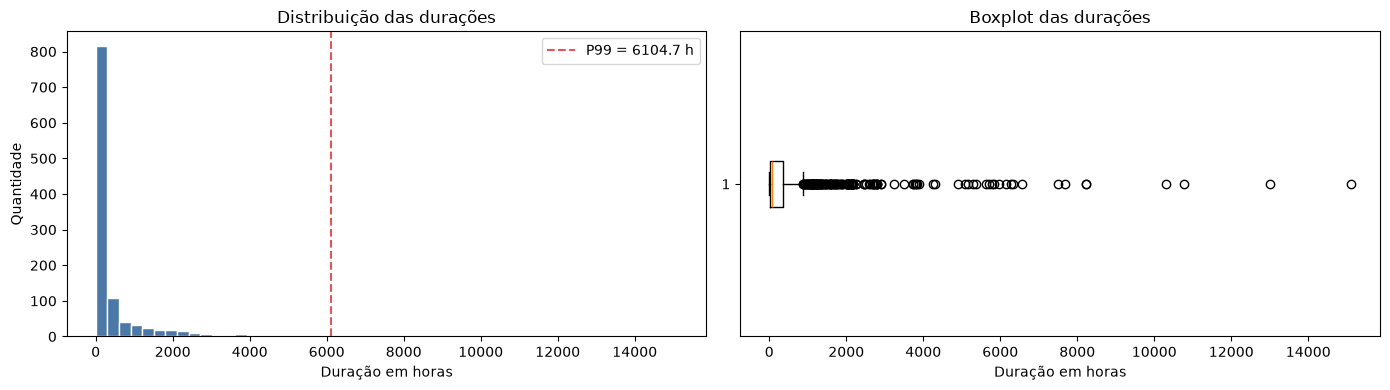

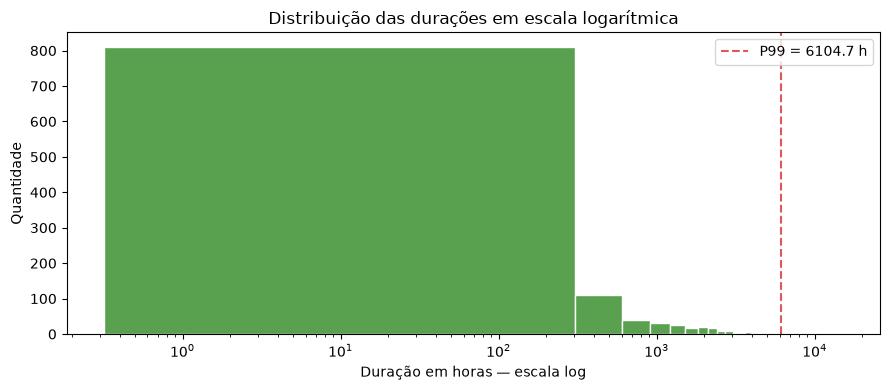

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 4)
)

axes[0].hist(
    duracoes,
    bins=50,
    color="#4C78A8",
    edgecolor="white"
)

axes[0].axvline(
    limite_99,
    color="#E15759",
    linestyle="--",
    label=f"P99 = {limite_99:.1f} h"
)

axes[0].set(
    title="Distribuição das durações",
    xlabel="Duração em horas",
    ylabel="Quantidade"
)

axes[0].legend()

axes[1].boxplot(
    duracoes,
    orientation="horizontal"
)

axes[1].set(
    title="Boxplot das durações",
    xlabel="Duração em horas"
)

plt.tight_layout()
plt.show()

duracoes_positivas = duracoes[
    duracoes > 0
]

plt.figure(figsize=(9, 4))

plt.hist(
    duracoes_positivas,
    bins=50,
    color="#59A14F",
    edgecolor="white"
)

plt.xscale("log")

plt.axvline(
    limite_99,
    color="#E15759",
    linestyle="--",
    label=f"P99 = {limite_99:.1f} h"
)

plt.title(
    "Distribuição das durações em escala logarítmica"
)
plt.xlabel("Duração em horas — escala log")
plt.ylabel("Quantidade")
plt.legend()
plt.tight_layout()
plt.show()

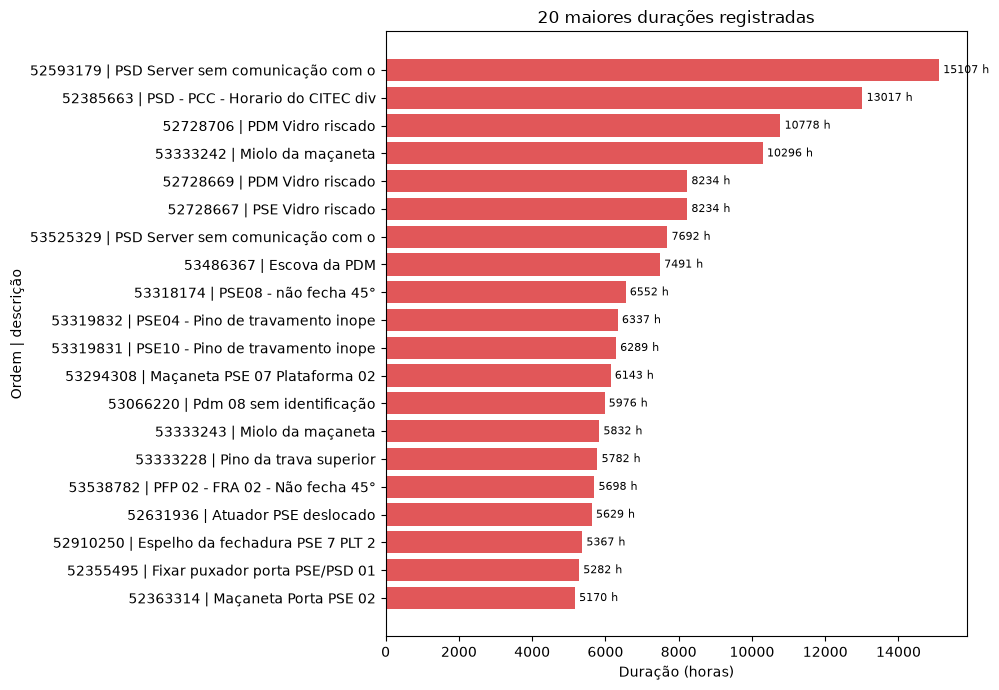

In [15]:
maiores_duracoes_plot = df_limpo.nlargest(20, "duracao_avaria_horas").sort_values("duracao_avaria_horas")
rotulos = (
    maiores_duracoes_plot["ordem"].fillna("SEM ORDEM")
    + " | "
    + maiores_duracoes_plot["descricao"].str.slice(0, 32)
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(rotulos, maiores_duracoes_plot["duracao_avaria_horas"], color="#E15759")
ax.set(title="20 maiores durações registradas", xlabel="Duração (horas)", ylabel="Ordem | descrição")
ax.bar_label(ax.containers[0], fmt="%.0f h", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

Os registros acima do percentil 99 e os casos com duração zero permanecem na base principal. Flags e tabelas de auditoria permitem tratá-los de maneira específica em análises futuras.

In [16]:
df_limpo["duracao_extrema_flag"] = (
    df_limpo["duracao_avaria_horas"] > limite_99
)

df_limpo["duracao_zero_flag"] = (
    df_limpo["duracao_avaria_horas"].eq(0)
)

df_limpo[["duracao_extrema_flag", "duracao_zero_flag"]].sum()

duracoes_extremas = df_limpo.loc[
    df_limpo["duracao_extrema_flag"]
].copy()

registros_duracao_zero = df_limpo.loc[
    df_limpo["duracao_zero_flag"]
].copy()

print("Durações extremas preservadas:", len(duracoes_extremas))
print("Durações iguais a zero preservadas:", len(registros_duracao_zero))

registros_duracao_zero[
    [
        "linha_origem",
        "nota",
        "ordem",
        "descricao",
        "inicio_avaria_datetime",
        "fim_avaria_datetime",
        "encerramento_datetime",
        "status_do_usuario_da_ordem"
    ]
]

decisoes_limpeza["duracao_extrema"] = (
    f"Foram sinalizados {len(duracoes_extremas)} registros "
    f"acima do percentil 99 ({limite_99:.2f} horas). "
    "Os registros foram mantidos por não haver evidência de erro temporal."
)

decisoes_limpeza["duracao_zero"] = (
    f"Foram sinalizados {len(registros_duracao_zero)} registros com "
    "duração igual a zero, mantidos sem imputação."
)

decisoes_limpeza["colunas_esparsas"] = (
    "As colunas comentarios_classificacao_engenharia e analise_datetime "
    "foram removidas da base final por apresentarem apenas 1 registro "
    "preenchido entre 1.163 linhas. As marcações foram preservadas nas "
    "flags indisponivel_flag e analisada_flag."
)

pd.Series(decisoes_limpeza)

relatorio_ausentes_limpo = pd.DataFrame({
    "quantidade": df_limpo.isna().sum(),
    "percentual": (df_limpo.isna().mean() * 100).round(2)
}).sort_values("percentual", ascending=False)

relatorio_ausentes_limpo[
    relatorio_ausentes_limpo["quantidade"] > 0
]

Durações extremas preservadas: 12
Durações iguais a zero preservadas: 5


,quantidade,percentual
comentarios_classificacao_engenharia,1162,99.91
analisada,1162,99.91
indisponivel,1162,99.91
analise_datetime,1162,99.91
data_analise,1162,99.91
acao,43,3.70
causa,42,3.61
fim_da_avaria,39,3.35
fim_avaria_datetime,39,3.35
objeto,39,3.35


## 8. Preparação da base final

As colunas temporárias são removidas após a validação. As marcações originais são substituídas por flags. O comentário de engenharia e o instante de análise são retirados da base final por apresentarem somente um valor preenchido entre 1.163 registros.

In [17]:
df_final = df_limpo.copy()

colunas_temporarias = [
    "inicio_avaria",
    "hora_inicio_avaria",
    "hora_inicio_avaria_convertida",
    "fim_da_avaria",
    "hora_do_fim_da_avaria",
    "hora_do_fim_da_avaria_convertida",
    "data_analise",
    "hora_analise",
    "hora_analise_convertida",
    "analise_datetime",
    "comentarios_classificacao_engenharia",
    "encerram_por_data",
    "hora_de_encerramento",
    "hora_de_encerramento_convertida",
    "indisponivel",
    "analisada"
]

df_final.drop(
    columns=colunas_temporarias,
    inplace=True,
    errors="ignore"
)

colunas_inicio = [
    "linha_origem",
    "tipo_de_nota",
    "nota",
    "ordem",
    "perfil_do_catalogo",
    "descricao",
    "local_de_instalacao",
    "centro_de_trabalho_responsavel",
    "inicio_avaria_datetime",
    "fim_avaria_datetime",
    "duracao_avaria_horas",
    "encerramento_datetime",
    "indisponivel_flag",
    "analisada_flag",
    "ordem_ausente_flag",
    "ordem_repetida_flag",
    "nota_repetida_flag",
    "duracao_extrema_flag",
    "duracao_zero_flag"
]

outras_colunas = [
    coluna for coluna in df_final.columns
    if coluna not in colunas_inicio
]

df_final = df_final[colunas_inicio + outras_colunas]

print("Dimensão final:", df_final.shape)
df_final.info()

Dimensão final: (1163, 27)
<class 'pandas.DataFrame'>
RangeIndex: 1163 entries, 0 to 1162
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   linha_origem                    1163 non-null   int64         
 1   tipo_de_nota                    1163 non-null   string        
 2   nota                            1163 non-null   string        
 3   ordem                           1158 non-null   string        
 4   perfil_do_catalogo              1163 non-null   string        
 5   descricao                       1163 non-null   string        
 6   local_de_instalacao             1163 non-null   string        
 7   centro_de_trabalho_responsavel  1163 non-null   string        
 8   inicio_avaria_datetime          1163 non-null   datetime64[us]
 9   fim_avaria_datetime             1124 non-null   datetime64[us]
 10  duracao_avaria_horas            1124 non-null   float64 

## 9. Validação final

As asserções verificam o balanço de registros, tipos dos identificadores, duplicidades, coerência temporal e nomes de colunas.

In [18]:
validacao_final = pd.Series({
    "linhas_originais": len(df),
    "linhas_finais": len(df_final),
    "colunas_finais": df_final.shape[1],
    "duplicatas_exatas": df_limpo.duplicated(
        subset=colunas_comparacao
    ).sum(),
    "notas_ausentes": df_final["nota"].isna().sum(),
    "ordens_ausentes": df_final["ordem"].isna().sum(),
    "duracoes_negativas": df_final["duracao_avaria_horas"].lt(0).sum(),
    "duracoes_extremas_sinalizadas": df_final["duracao_extrema_flag"].sum(),
    "duracoes_zero_sinalizadas": df_final["duracao_zero_flag"].sum(),
    "colunas_duplicadas": df_final.columns.duplicated().sum()
})

assert len(df_final) == len(df)
assert df_limpo.duplicated(subset=colunas_comparacao).sum() == 0
assert df_final["nota"].dtype.name == "string"
assert df_final["ordem"].dtype.name == "string"
assert df_final["inicio_avaria_datetime"].notna().all()
assert not df_final["duracao_avaria_horas"].lt(0).any()
assert not df_final.columns.duplicated().any()

validacao_final

relatorio_ausentes_final = pd.DataFrame({
    "coluna": df_final.columns,
    "quantidade_ausente": [
        df_final[coluna].isna().sum()
        for coluna in df_final.columns
    ],
    "percentual_ausente": [
        round(df_final[coluna].isna().mean() * 100, 2)
        for coluna in df_final.columns
    ]
}).sort_values("percentual_ausente", ascending=False)

relatorio_decisoes = pd.DataFrame(
    decisoes_limpeza.items(),
    columns=["campo_ou_regra", "decisao"]
)

duracoes_extremas_final = df_final.loc[
    df_final["duracao_extrema_flag"]
].copy()

duracoes_zero_final = df_final.loc[
    df_final["duracao_zero_flag"]
].copy()

relatorio_ausentes_final.head(15)

,coluna,quantidade_ausente,percentual_ausente
26,acao,43,3.70
25,causa,42,3.61
9,fim_avaria_datetime,39,3.35
23,objeto,39,3.35
24,defeito,39,3.35
10,duracao_avaria_horas,39,3.35
11,encerramento_datetime,7,0.60
20,texto_longo_da_ordem,7,0.60
19,status_do_usuario_da_ordem,5,0.43
21,status_do_sistema_da_ordem,5,0.43


## 10. Exportação

O arquivo original não é sobrescrito. O resultado inclui a base limpa, tabelas de auditoria das durações e relatórios de qualidade e decisões.

In [19]:
from pathlib import Path

pasta_saida = Path(caminho_1).parent / "processados"
pasta_saida.mkdir(parents=True, exist_ok=True)
arquivo_saida = pasta_saida / "ZM02_limpa.xlsx"

with pd.ExcelWriter(arquivo_saida, engine="openpyxl") as writer:
    df_final.to_excel(writer, sheet_name="ZM02_limpa", index=False)
    duracoes_extremas_final.to_excel(
        writer, sheet_name="Duracoes_extremas", index=False
    )
    duracoes_zero_final.to_excel(
        writer, sheet_name="Duracoes_zero", index=False
    )
    relatorio_ausentes_final.to_excel(
        writer, sheet_name="Qualidade_ausencias", index=False
    )
    relatorio_decisoes.to_excel(
        writer, sheet_name="Decisoes_limpeza", index=False
    )

print("Arquivo exportado para:", arquivo_saida.resolve())

Arquivo exportado para: C:\Users\Inteli\Downloads\EC-M7\g04\data\Corretiva Programada\processados\ZM02_limpa.xlsx
